Set project paths, reproducibility, runtime device, and the binary label mapping.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src" / "faces_model.py").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Could not locate project src/faces_model.py")
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.faces_model import (build_model, evaluate, fit, get_transforms,
                             make_loader, set_seed)

set_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CSV_DIR = PROJECT_ROOT / "data" / "faces"
TRAIN_CSV = CSV_DIR / "train_10k.csv"
VALID_CSV = CSV_DIR / "valid_2k.csv"
TEST_CSV = CSV_DIR / "test_2k.csv"
print("Device:", DEVICE)
print("Label mapping: real=1, fake=0; P(fake) is softmax class 0")

Device: cpu
Label mapping: real=1, fake=0; P(fake) is softmax class 0


Load ImageNet-pretrained EfficientNet-B0 and report total/trainable parameter counts.

In [2]:
model = build_model(pretrained=True)
total_parameters = sum(parameter.numel() for parameter in model.parameters())
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
model = model.to(DEVICE)

Total parameters: 4,010,110
Trainable parameters: 4,010,110


Freeze the feature backbone and train the classification head for two epochs on the stratified smoke-test subsets.

In [3]:
train_loader_phase1 = make_loader(TRAIN_CSV, train=True, batch_size=32, limit=2000, seed=42)
valid_loader = make_loader(VALID_CSV, train=False, batch_size=32, limit=500, seed=42)
for parameter in model.features.parameters():
    parameter.requires_grad = False
for parameter in model.classifier.parameters():
    parameter.requires_grad = True

phase1_history = fit(
    model, train_loader_phase1, valid_loader, epochs=2, lr=1e-3,
    patience=3, device=DEVICE, seed=42,
)
print("Phase 1 epoch seconds:", [round(row["seconds"], 1) for row in phase1_history])

Epoch 1/2 - train loss=0.6117, acc=0.6625; val loss=0.5496, acc=0.7200; seconds=124.3
Epoch 2/2 - train loss=0.5175, acc=0.7475; val loss=0.5426, acc=0.7080; seconds=88.1
Phase 1 epoch seconds: [124.3, 88.1]


Unfreeze the final two EfficientNet feature blocks and fine-tune them with a lower learning rate for one epoch.

In [4]:
for block in model.features[-2:]:
    for parameter in block.parameters():
        parameter.requires_grad = True
for parameter in model.classifier.parameters():
    parameter.requires_grad = True

train_loader_phase2 = make_loader(TRAIN_CSV, train=True, batch_size=32, limit=2000, seed=42)
phase2_history = fit(
    model, train_loader_phase2, valid_loader, epochs=1,
    backbone_lr=1e-4, head_lr=1e-3, patience=2, device=DEVICE, seed=42,
)
print("Phase 2 epoch seconds:", [round(row["seconds"], 1) for row in phase2_history])

Epoch 1/1 - train loss=0.4673, acc=0.7820; val loss=0.4565, acc=0.7880; seconds=88.4
Phase 2 epoch seconds: [88.4]


Estimate one-epoch training time for 10,000 and 100,000 images from the measured phase speeds.

In [5]:
measured_train_seconds = sum(row["seconds"] for row in phase1_history + phase2_history)
measured_train_images = 2000 * len(phase1_history) + 2000 * len(phase2_history)
seconds_per_image = measured_train_seconds / measured_train_images
print(f"Measured training speed: {seconds_per_image:.4f} seconds/image")
for image_count, description in [(10_000, "train_10k"), (100_000, "full train.csv")]:
    projected_seconds = seconds_per_image * image_count
    print(f"Projected one-epoch time for {description} ({image_count:,} images): "
          f"{projected_seconds / 60:.1f} minutes ({projected_seconds / 3600:.2f} hours)")

Measured training speed: 0.0502 seconds/image
Projected one-epoch time for train_10k (10,000 images): 8.4 minutes (0.14 hours)
Projected one-epoch time for full train.csv (100,000 images): 83.6 minutes (1.39 hours)


Evaluate on 500 stratified test images and report clearly labeled CPU smoke-test classification metrics.

In [6]:
test_loader = make_loader(TEST_CSV, train=False, batch_size=32, limit=500, seed=42)
test_results = evaluate(model, test_loader, device=DEVICE)
test_labels = test_results["labels"]
test_predictions = test_results["predictions"]
print("CPU SMOKE TEST ONLY (500-image stratified test subset; not final results)")
print(f"Loss: {test_results['loss']:.4f}")
print(f"Accuracy: {test_results['accuracy']:.4f}")
print(f"Fake precision: {precision_score(test_labels, test_predictions, pos_label=0, zero_division=0):.4f}")
print(f"Fake recall: {recall_score(test_labels, test_predictions, pos_label=0, zero_division=0):.4f}")
print(f"Fake F1: {f1_score(test_labels, test_predictions, pos_label=0, zero_division=0):.4f}")
print("Confusion matrix (rows=true [fake, real], columns=predicted [fake, real]):")
print(confusion_matrix(test_labels, test_predictions, labels=[0, 1]))
print(f"ROC-AUC using P(fake): {roc_auc_score(test_labels == 0, test_results['p_fake']):.4f}")

CPU SMOKE TEST ONLY (500-image stratified test subset; not final results)
Loss: 0.4187
Accuracy: 0.8060
Fake precision: 0.8048
Fake recall: 0.8080
Fake F1: 0.8064
Confusion matrix (rows=true [fake, real], columns=predicted [fake, real]):
[[202  48]
 [ 49 201]]
ROC-AUC using P(fake): 0.8961


Plot train/validation loss and accuracy across both phases, marking the phase boundary.

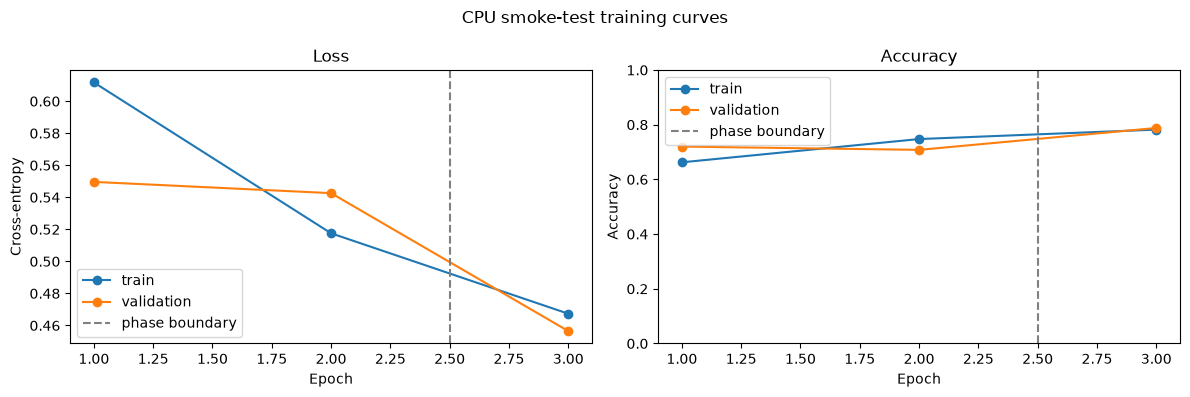

Seconds per epoch: [124.3, 88.1, 88.4]


In [9]:
all_history = phase1_history + phase2_history
epochs = np.arange(1, len(all_history) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, [row["train_loss"] for row in all_history], marker="o", label="train")
axes[0].plot(epochs, [row["val_loss"] for row in all_history], marker="o", label="validation")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy")
axes[1].plot(epochs, [row["train_acc"] for row in all_history], marker="o", label="train")
axes[1].plot(epochs, [row["val_acc"] for row in all_history], marker="o", label="validation")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
for axis in axes:
    axis.axvline(len(phase1_history) + 0.5, color="gray", linestyle="--", label="phase boundary")
    axis.legend()
fig.suptitle("CPU smoke-test training curves")
fig.tight_layout()
plt.show()
print("Seconds per epoch:", [round(row["seconds"], 1) for row in all_history])

Display up to eight misclassified test images with their true and predicted labels.

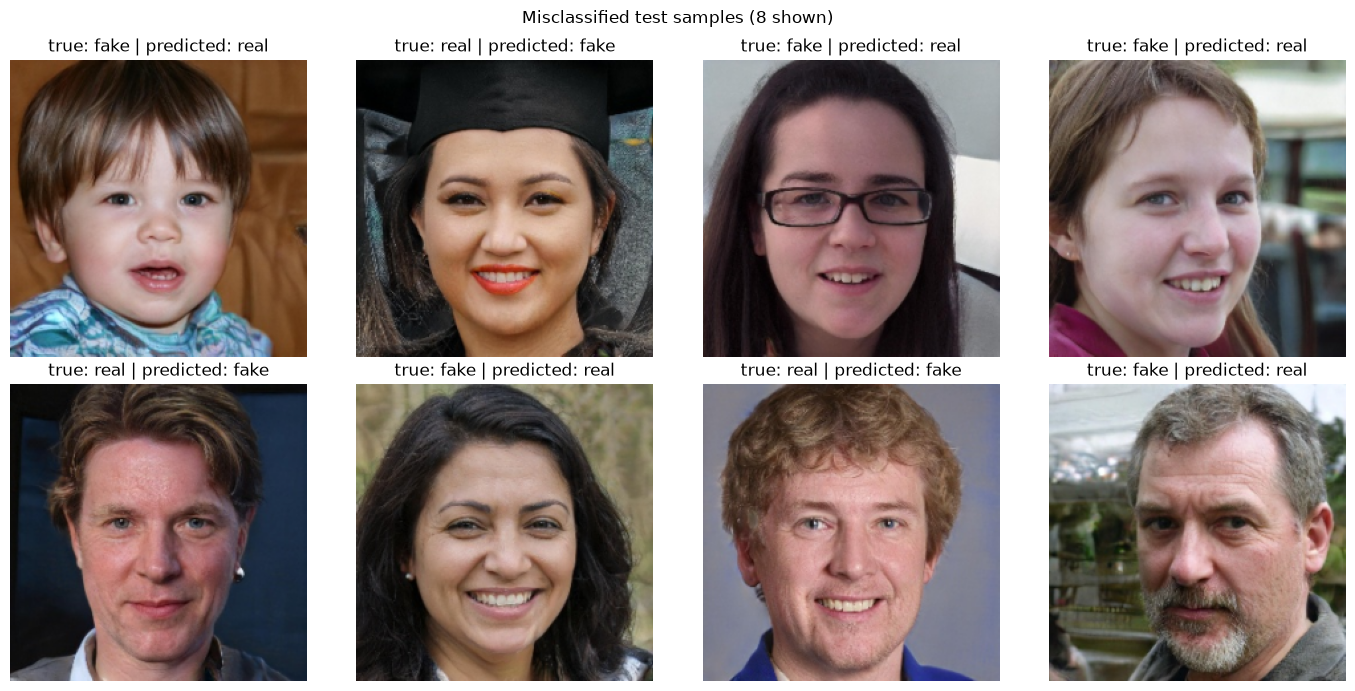

Misclassified images shown: 8


In [7]:
from src.datasets import CsvImageDataset

misclassified = np.flatnonzero(test_labels != test_predictions)[:8]
test_display_dataset = CsvImageDataset(TEST_CSV, transform=get_transforms(train=False))
mean = torch.tensor((0.485, 0.456, 0.406)).view(3, 1, 1)
std = torch.tensor((0.229, 0.224, 0.225)).view(3, 1, 1)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for axis, sample_index in zip(axes.flat, misclassified):
    image_tensor, _ = test_display_dataset[int(sample_index)]
    image = (image_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    true_label = "real" if test_labels[sample_index] == 1 else "fake"
    predicted_label = "real" if test_predictions[sample_index] == 1 else "fake"
    axis.imshow(image)
    axis.set_title(f"true: {true_label} | predicted: {predicted_label}")
    axis.axis("off")
for axis in axes.flat[len(misclassified):]:
    axis.axis("off")
fig.suptitle(f"Misclassified test samples ({len(misclassified)} shown)")
fig.tight_layout()
plt.show()
print(f"Misclassified images shown: {len(misclassified)}")

Save the trained model state dictionary to the Git-ignored models directory.

In [8]:
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "effnet_b0_smoke.pth"
torch.save(model.state_dict(), MODEL_PATH)
print("Saved state_dict:", MODEL_PATH)
print("Weight file bytes:", MODEL_PATH.stat().st_size)

Saved state_dict: C:\Users\User\Deepfake-Blockchain-Project\models\effnet_b0_smoke.pth
Weight file bytes: 16336735
